In [2]:
import os
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

In [3]:
!wget --no-check-certificate "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip" -O "/tmp/cats-and-dogs.zip"

--2025-07-26 21:28:42--  https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip
Resolving download.microsoft.com (download.microsoft.com)... 2.21.185.113
Connecting to download.microsoft.com (download.microsoft.com)|2.21.185.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 824887076 (787M) [application/octet-stream]
Saving to: ‘/tmp/cats-and-dogs.zip’

/tmp/cats-and-dogs. 100%[===================>] 786.67M  57.8MB/s    in 13s     

2025-07-26 21:28:54 (61.8 MB/s) - ‘/tmp/cats-and-dogs.zip’ saved [824887076/824887076]



In [4]:
def get_valid(file_path):
    correct_files = []
    for name in os.listdir(file_path):
        try:
            img = Image.open(file_path + "/" + name)
            correct_files.append(name)
        except UnidentifiedImageError:
            pass
    return correct_files

In [6]:
local_zip = '/tmp/cats-and-dogs.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/tmp')
zip_ref.close()
classes = ['Cat', 'Dog']
original_cat_path = '/tmp/PetImages/Cat'
original_dog_path = '/tmp/PetImages/Dog'
original_cat = get_valid(original_cat_path)
original_dog = get_valid(original_dog_path)
random.seed(101)

random.shuffle(original_cat)
random.shuffle(original_dog)
size = min(len(original_cat), len(original_dog))
train_size = int(np.floor(0.7 * size))

valid_size = int(np.floor(0.2 * size))
test_size = size - train_size - valid_size
base_directory = 'dataset'
if not os.path.exists(base_directory):
    os.mkdir(base_directory)
type_datasets = ['train', 'valid', 'test']
directories = {}

for type_dataset in type_datasets:
    directory = os.path.join(base_directory, type_dataset)
    if not os.path.exists(directory):
        os.mkdir(directory)
    for name_class in classes:
        animal = os.path.join(directory, name_class)
        if not os.path.exists(animal):
            os.mkdir(animal)
        directories[f'{type_dataset}_{name_class}'] = animal+'/'
index = 0

for name_cat, name_dog in zip(original_cat, original_dog):
        if index <= train_size:
            type_of_dataset = 'train'
        elif train_size < index <= (train_size + valid_size):
            type_of_dataset = 'valid'
        elif (train_size + valid_size) < index <= (train_size + valid_size + test_size):
            type_of_dataset = 'test'
        shutil.copyfile(src=(original_cat_path + '/' +name_cat), dst=(directories[f'{type_of_dataset}_Cat']+name_cat))
        shutil.copyfile(src=(original_dog_path + '/' + name_dog), dst=(directories[f'{type_of_dataset}_Dog']+name_dog))
        index += 1

print(f'Dog - train: {len(os.listdir(directories["train_Dog"]))}\tCat - train: {len(os.listdir(directories["train_Cat"]))}')
print(f'Dog - valid: {len(os.listdir(directories["valid_Dog"]))}\tCat - valid: {len(os.listdir(directories["valid_Cat"]))}')
print(f'Dog - test:  {len(os.listdir(directories["test_Dog"]))}\tCat - test:  {len(os.listdir(directories["test_Cat"]))}')

Dog - train: 8750	Cat - train: 8750
Dog - valid: 2499	Cat - valid: 2499
Dog - test:  1250	Cat - test:  1250


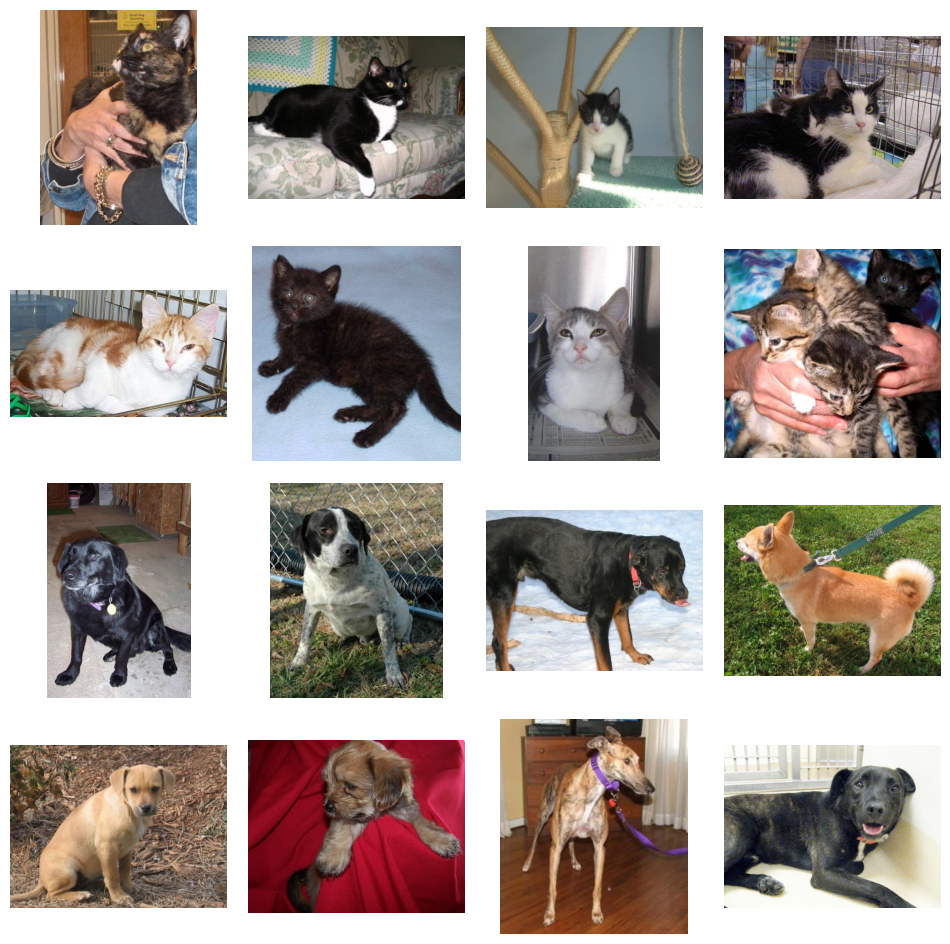

In [7]:
fig = plt.figure(figsize = (12, 12))
fig.subplots_adjust(hspace=0.1, wspace=0.1)
for i, element in enumerate(os.listdir(os.path.join(directories["train_Cat"]))[:8]):
    ax = fig.add_subplot(4, 4, i+1)
    img = Image.open(directories["train_Cat"]+element)
    ax.imshow(img)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

for i, element in enumerate(os.listdir(os.path.join(directories["train_Dog"]))[:8]):
    ax = fig.add_subplot(4, 4, i+9)
    img = Image.open(directories["train_Dog"]+element)
    ax.imshow(img)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

plt.show()

In [8]:
img_width, img_height = 150, 150
train_data_dir = 'dataset/train/'
validation_data_dir = 'dataset/valid/'
epochs = 1000
batch_size = 64
steps_per_epoch = train_size // batch_size
validation_steps = valid_size // batch_size
patience = 5
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_directory(train_data_dir,
                                                    target_size=(img_height, img_width),
                                                    batch_size=batch_size, class_mode='binary')
validation_generator = test_datagen.flow_from_directory(validation_data_dir,
                                                        target_size=(img_height, img_width),
                                                        batch_size=batch_size, class_mode='binary')
train_datagen_augmentation = ImageDataGenerator(rescale=1./255,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   rotation_range=30,
                                   horizontal_flip=True)
train_generator_augmentation = train_datagen_augmentation.flow_from_directory(train_data_dir,
                                                    target_size=(img_height, img_width),
                                                    batch_size=batch_size, class_mode='binary')

Found 17500 images belonging to 2 classes.
Found 4998 images belonging to 2 classes.
Found 17500 images belonging to 2 classes.


In [9]:
models = []
if not os.path.exists('history'):
    os.mkdir("history")
if not os.path.exists('charts'):
    os.mkdir("charts")

In [11]:
es = EarlyStopping(patience=patience, monitor='val_accuracy', restore_best_weights=True)


In [12]:
def show():
    max_index = 0
    min_accuracy = 1
    max_loss = 0
    colors = plt.cm.rainbow(np.linspace(0, 1, len(models)))

    for model in models:
        df = pd.read_csv(f'history/history_{model}.csv', index_col=0)
        df.index += 1
        if max_index < max(df.index):
            max_index = max(df.index)
        if min_accuracy > min(df[['accuracy', 'val_accuracy']].min()):
            min_accuracy = min(df[['accuracy', 'val_accuracy']].min())
        if max_loss < max(df[['loss', 'val_loss']].max()):
            max_loss = max(df[['loss', 'val_loss']].max())

    for model in models:
        df = pd.read_csv(f'history/history_{model}.csv', index_col=0)
        df.index += 1
        fig = plt.figure(figsize=(16,12))
        ax = fig.add_subplot(211)
        ax.plot(df['accuracy'], "bp--")
        ax.plot(df['val_accuracy'], "rp--")
        ax.set_title(f'Model {model} Accuracy', fontsize=20)
        ax.set_ylabel('Accuracy', fontsize=15)
        ax.set_xlabel('Epoch', fontsize=15)
        ax.set_xlim([1, max_index])
        ax.set_ylim([min_accuracy, 1])

        for milestone in (0.7, 0.8, 0.9, 0.95):
            ax.axhline(milestone, color="k", linestyle="--")
            try:
                if min(df[df['val_accuracy'] >= milestone].index) > 1:
                    plt.axvline(min(df[df['val_accuracy'] >= milestone].index), color="g", linestyle="--")
                    ax.text(min(df[df['val_accuracy'] >= milestone].index)+0.6, min_accuracy+0.02,
                            f'Epoch: {min(df[df["val_accuracy"] >= milestone].index)}', rotation=90)
            except:
                pass

        plt.legend(['Training', 'Validation'], loc='lower right')
        ax = fig.add_subplot(212)
        ax.plot(df['loss'], "bp--")
        ax.plot(df['val_loss'], "rp--")
        ax.set_title(f'Model {model} Loss', fontsize=20)
        ax.set_ylabel('Loss', fontsize=15)
        ax.set_xlabel('Epoch', fontsize=15)
        ax.set_xlim([1, max_index])
        ax.set_ylim([0, max_loss])
        ax.legend(['Training', 'Validation'], loc='upper right')
        plt.tight_layout()
        plt.savefig(f'charts/train_history_{model}.png', transparent=True, dpi=600)
        plt.show()

    fig = plt.figure(figsize=(16,12))
    ax = fig.add_subplot(211)
    for model, color in zip(models, colors):
        df = pd.read_csv(f'history/history_{model}.csv', index_col=0)
        df.index += 1
        ax.plot(df['val_accuracy'], label=f'Model {model}', color=color, linewidth=3)
        ax.axhline(df['val_accuracy'].max(), color=color, linestyle="dotted", linewidth=4)

    ax.set_title(f'Accuracy', fontsize=20)
    ax.set_ylabel('Accuracy', fontsize=15)
    ax.set_xlabel('Epoch', fontsize=15)
    ax.set_xlim([1, max_index])
    ax.set_ylim([min_accuracy, 1])
    for milestone in (0.7, 0.8, 0.9, 0.95):
        ax.axhline(milestone, color="k", linestyle="--")
    plt.legend(loc='lower right')
    ax = fig.add_subplot(212)
    for model, color in zip(models, colors):
        df = pd.read_csv(f'history/history_{model}.csv', index_col=0)
        df.index += 1
        ax.plot(df['val_loss'], label=f'Model {model}', color=color, linewidth=3)
        ax.axhline(df['val_loss'].min(), color=color, linestyle="dotted", linewidth=4)
    ax.set_title(f'Loss', fontsize=20)
    ax.set_ylabel('Loss', fontsize=15)
    ax.set_xlabel('Epoch', fontsize=15)
    ax.set_xlim([1, max_index])
    ax.set_ylim([0, max_loss])
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.savefig(f'charts/train_history_of_each_model.png', transparent=True, dpi=600)
    plt.show()

# Model

In [13]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras import regularizers
from tensorflow.keras.layers import BatchNormalization

vgg16 = VGG16(weights='imagenet', include_top=False, input_shape=(150, 150, 3))
vgg16.trainable = True

set_trainable = False
for layer in vgg16.layers:
    if layer.name == 'block5_conv1':
        set_trainable = True
    if set_trainable:
        layer.trainable = True
    else:
        layer.trainable = False

for layer in vgg16.layers:
    print(f'layer_name: {layer.name:13} trainable: {layer.trainable}')

model = Sequential()
model.add(vgg16)

#Dodatkowe warstwy splotowe
model.add(Conv2D(64, (3,3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(0.001)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.3))

model.add(Conv2D(32, (3,3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(0.001)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.3))

model.add(Flatten())
model.add(Dropout(0.5))
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(64, activation='relu'))
model.add(Dense(units=1, activation='sigmoid'))
model.compile(loss='binary_crossentropy',
                       optimizer=RMSprop(learning_rate=1e-4),
                       metrics=['accuracy'])
model.summary()
models.append("my_model")

layer_name: input_layer_2 trainable: False
layer_name: block1_conv1  trainable: False
layer_name: block1_conv2  trainable: False
layer_name: block1_pool   trainable: False
layer_name: block2_conv1  trainable: False
layer_name: block2_conv2  trainable: False
layer_name: block2_pool   trainable: False
layer_name: block3_conv1  trainable: False
layer_name: block3_conv2  trainable: False
layer_name: block3_conv3  trainable: False
layer_name: block3_pool   trainable: False
layer_name: block4_conv1  trainable: False
layer_name: block4_conv2  trainable: False
layer_name: block4_conv3  trainable: False
layer_name: block4_pool   trainable: False
layer_name: block5_conv1  trainable: True
layer_name: block5_conv2  trainable: True
layer_name: block5_conv3  trainable: True
layer_name: block5_pool   trainable: True


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 4, 4, 64)       │       294,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 2, 2, 32)       │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 2, 2, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 1, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,078,177 (57.52 MB)

 Trainable params: 7,442,721 (28.39 MB)

 Non-trainable params: 7,635,456 (29.13 MB)

In [14]:
es = EarlyStopping(patience=patience, monitor='val_accuracy', restore_best_weights=True)
history_my_model = model.fit(train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=epochs,
    validation_data=validation_generator,
    validation_steps=validation_steps,
    callbacks=[es])

history_my_model_df = pd.DataFrame(history_my_model.history)
history_my_model_csv = 'history/history_my_model.csv'

with open(history_my_model_csv, mode='w') as f:
    history_my_model_df.to_csv(f)

Epoch 1/1000


/Users/jtadych/Code/venv312/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


136/136 ━━━━━━━━━━━━━━━━━━━━ 348s 3s/step - accuracy: 0.5241 - loss: 0.9376 - val_accuracy: 0.8814 - val_loss: 0.6515
Epoch 2/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 359s 3s/step - accuracy: 0.7733 - loss: 0.6119 - val_accuracy: 0.8630 - val_loss: 0.4469
Epoch 3/1000
  2/136 ━━━━━━━━━━━━━━━━━━━━ 4:35 2s/step - accuracy: 0.8867 - loss: 0.4693

/Users/jtadych/Code/venv312/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


136/136 ━━━━━━━━━━━━━━━━━━━━ 74s 531ms/step - accuracy: 0.8829 - loss: 0.4472 - val_accuracy: 0.8490 - val_loss: 0.4737
Epoch 4/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 365s 3s/step - accuracy: 0.9209 - loss: 0.3796 - val_accuracy: 0.9159 - val_loss: 0.3325
Epoch 5/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 368s 3s/step - accuracy: 0.9392 - loss: 0.3050 - val_accuracy: 0.9275 - val_loss: 0.2964
Epoch 6/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 77s 550ms/step - accuracy: 0.9218 - loss: 0.2847 - val_accuracy: 0.8413 - val_loss: 0.5754
Epoch 7/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 364s 3s/step - accuracy: 0.9453 - loss: 0.2665 - val_accuracy: 0.9087 - val_loss: 0.3675
Epoch 8/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 356s 3s/step - accuracy: 0.9573 - loss: 0.2253 - val_accuracy: 0.9363 - val_loss: 0.2711
Epoch 9/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 75s 542ms/step - accuracy: 0.9608 - loss: 0.2854 - val_accuracy: 0.9427 - val_loss: 0.2632
Epoch 10/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 1392s 10s/step - accuracy: 0.9577 - loss: 0.213

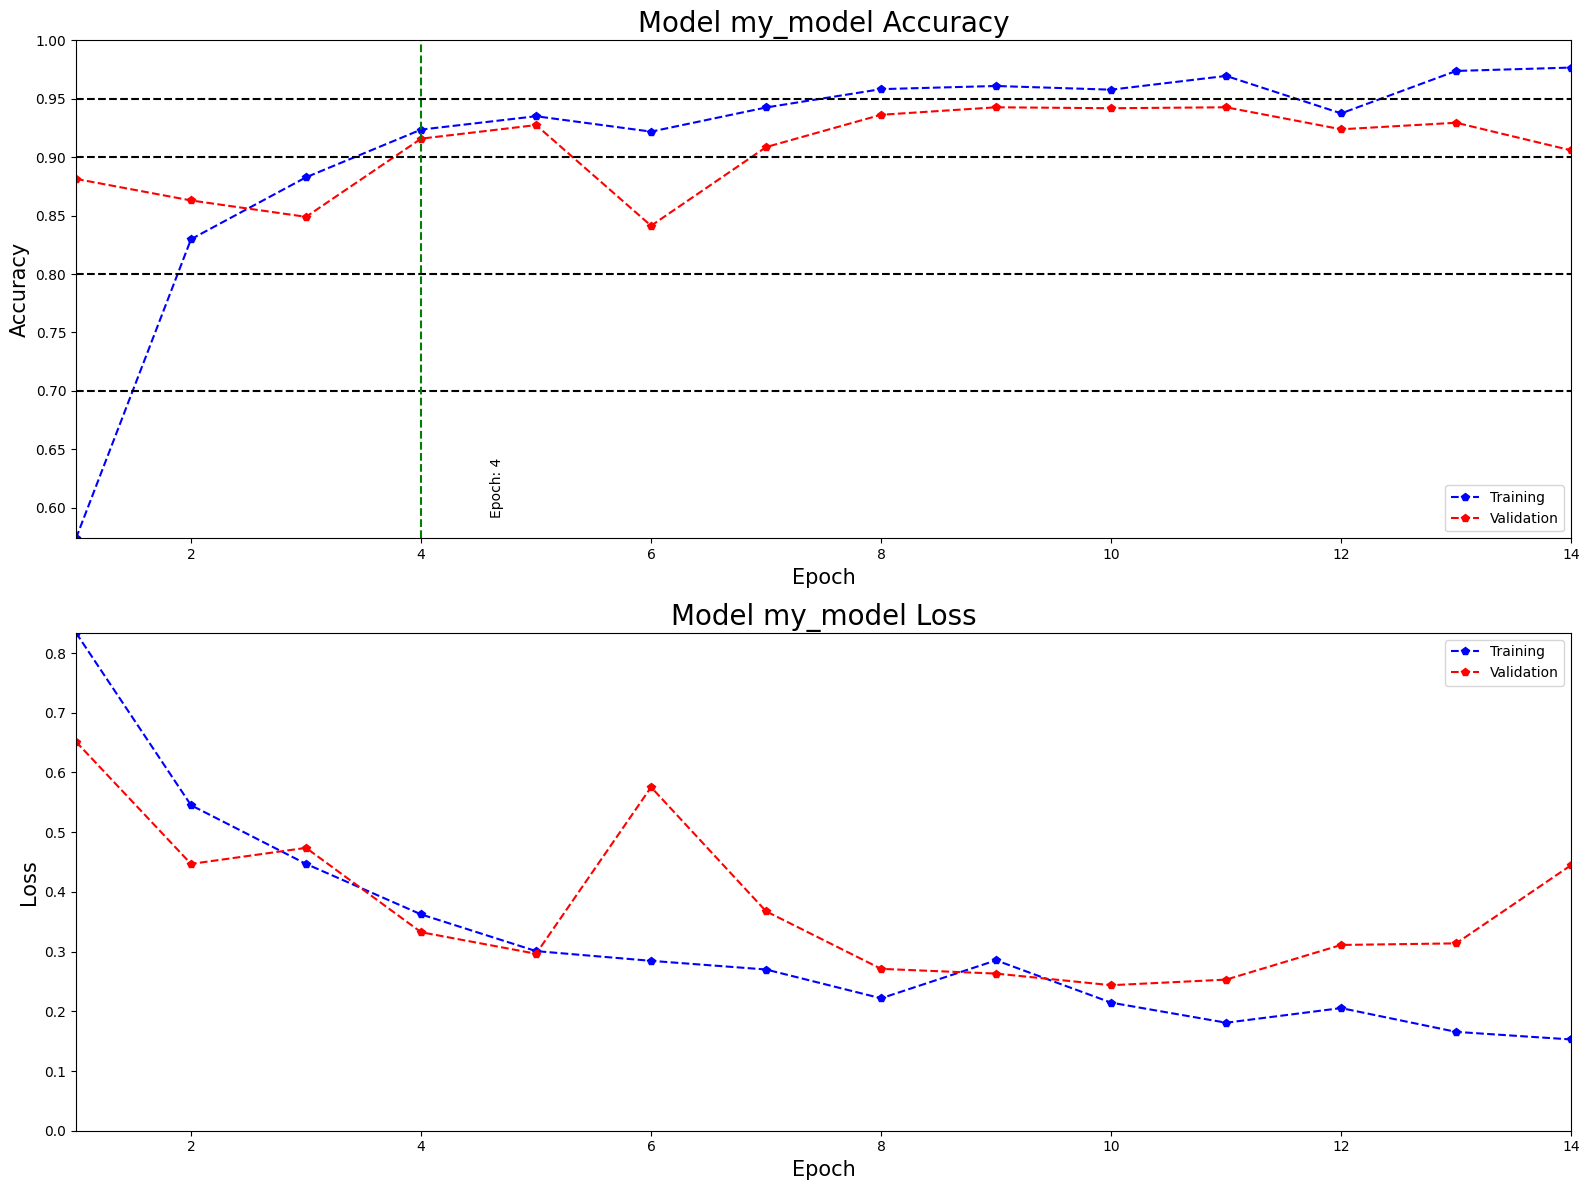

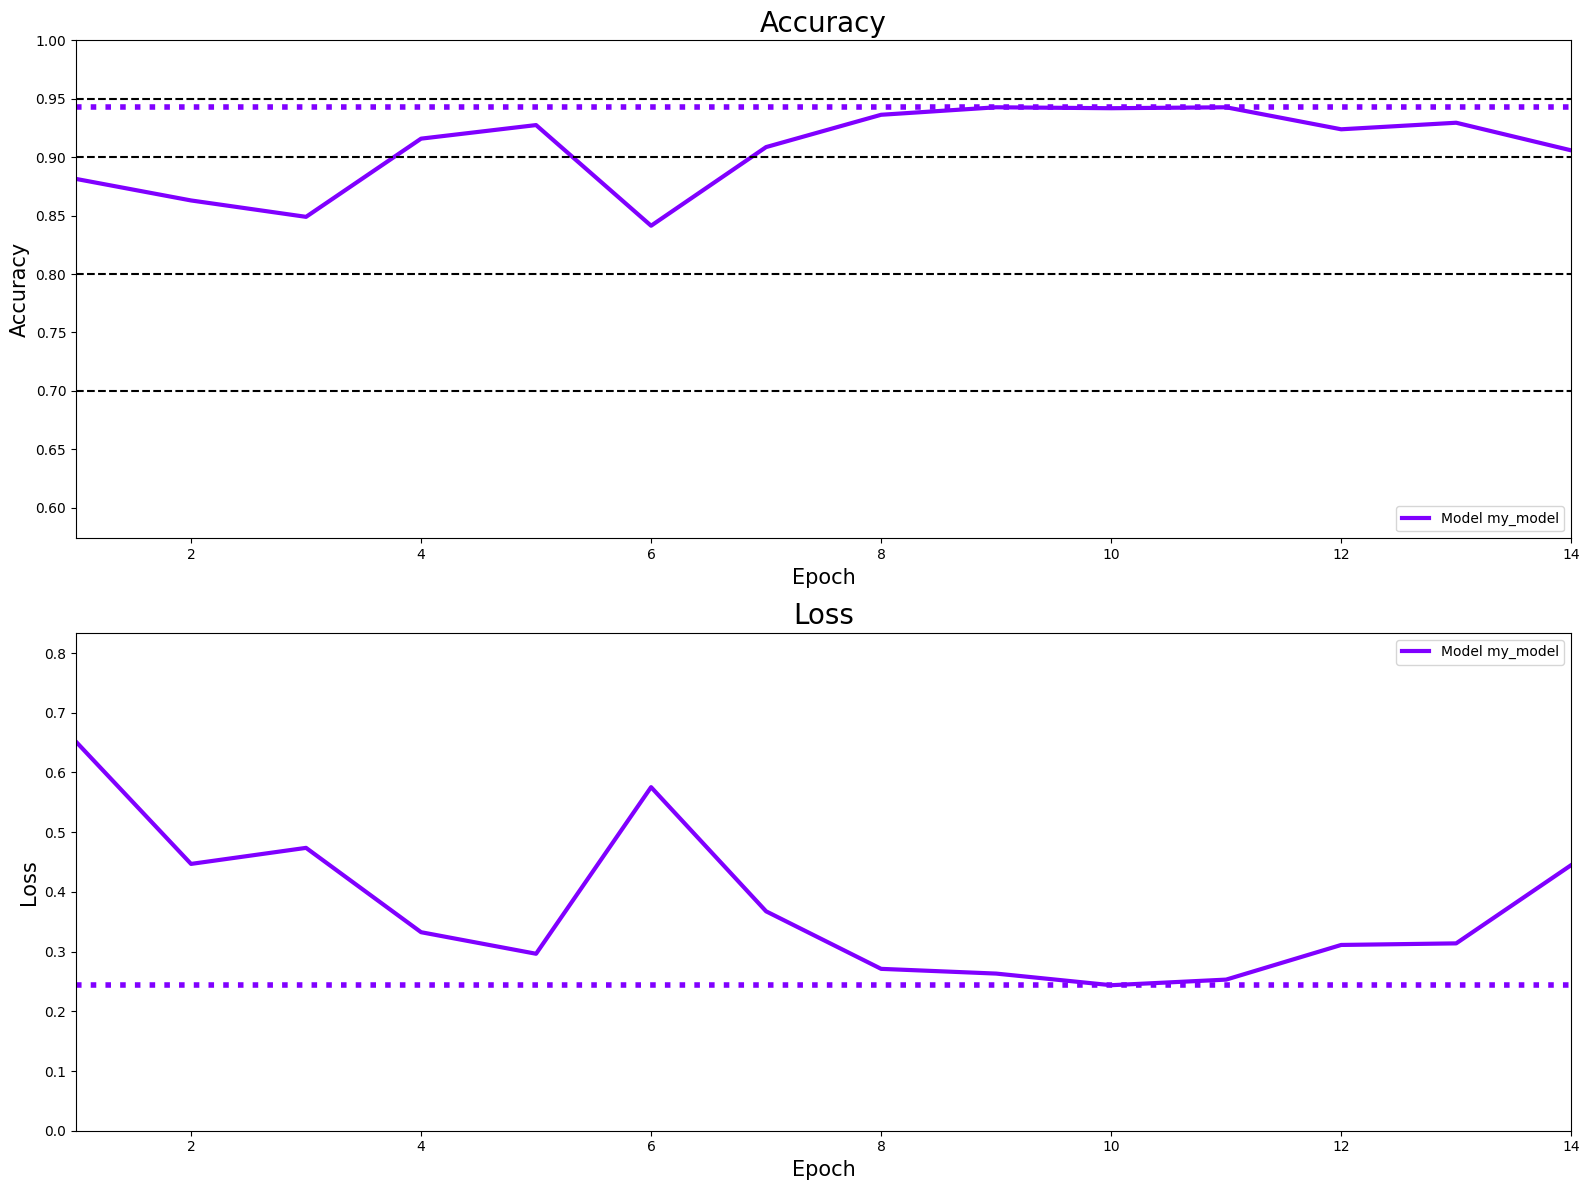

In [17]:
show()